# Arbeitspaket (AP) 5: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td></td></tr>
  <tr><td>Nachname:</td><td></td></tr>
  <tr><td>Immatrikulationsnummer:</td><td></td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Prüfungsdatum / Raum / Zeit:</td><td>[TT.MM.2026] / Raum: [anpassen] / [hh:mm – hh:mm]</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «PhoneMarkt» und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Geräts (Preisverlauf, technische Daten)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: Liste mit Kundenbewertungen pro <code>product_id</code></td></tr>
    <tr><td><code>smartphones_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `smartphone_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/home/claude/out/DS_HS2026_LNW_I_Examples/AP05


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.color')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'color',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (148, 9)


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,"6.67"" Display",5'110mAh,CHF 299.–,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,"6.82"" Display",6'000mAh,CHF 899.–,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,"6.3"" Display",4'870mAh,CHF 1'249.–,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,"6.7"" Display",5'000mAh,CHF 339.–,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('smartphones_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «PhoneMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Die gescrapten Rohdaten `df_raw` enthalten 148 Zeilen, der Shop führt aber nur 142 Artikel. Ein Kollege entfernt die Duplikate wie folgt:

```python
df_dedup = df_raw.drop_duplicates(subset=['brand', 'model'])
df_dedup.shape          # Ergebnis: (33, 9)
```

a) Warum ist dieses Vorgehen falsch? Begründen Sie mit den Shop-Daten.

b) Wie entstehen die Duplikate in `df_raw`, und wie entfernt man sie korrekt?

**Ihre Antwort:**

a) Dasselbe Modell (`brand` + `model`, z.B. Samsung Galaxy S25 Ultra) wird in mehreren **Varianten** verkauft — verschiedene Speichergrössen (`storage_raw`) und Farben (`color`) mit eigener `product_id` und eigenem Preis. Das sind verschiedene Artikel und keine Duplikate. Mit `subset=['brand', 'model']` bleibt pro Modell nur die erste Variante übrig: 33 statt 142 Artikel — es gehen 109 echte Produkte verloren, und alle Kennzahlen (z.B. Preise pro Marke) wären verzerrt.

b) Die Duplikate entstehen durch die **Paginierung**: Die letzten Produktkarten einer Seite erscheinen oben auf der nächsten Seite noch einmal (Überlappung). Diese Zeilen sind in **allen** Spalten identisch. Korrekt ist deshalb `df_raw.drop_duplicates()` (alle Spalten) bzw. `drop_duplicates(subset=['product_id'])`, weil `product_id` den Artikel eindeutig identifiziert — beides ergibt 142 Zeilen. Prüfen lässt sich das vorher mit `df_raw.duplicated(keep=False).sum()` (12 Zeilen = 6 Paare).

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 12 (Duplicated Values: «all values in at least one row … are identical»; `df.duplicated(keep=False)`, `df.drop_duplicates()`).*

### A2 (4 Punkte)

Ordnen Sie die drei Variablen `brand`, `availability` (`Sofort lieferbar`, `Lieferbar in 2–5 Tagen`, `Vorbestellung`) und `battery_mah` jeweils einem **Skalenniveau** zu (nominal, ordinal, metrisch). Nennen Sie für jede Variable ein **zulässiges Lagemass** (Modus, Median oder Mittelwert) und eine geeignete **univariate Grafik**. Begründen Sie kurz.

**Ihre Antwort:**

| Variable | Skalenniveau | Lagemass | Grafik |
|---|---|---|---|
| `brand` | **nominal** — Kategorien ohne natürliche Reihenfolge | Modus (häufigste Marke) | Balkendiagramm (Bar Chart) |
| `availability` | **ordinal** — Kategorien mit Rangfolge nach Lieferzeit (sofort < 2–5 Tage < Vorbestellung), Abstände aber nicht messbar | Median (bzw. Modus) | Balkendiagramm in der Reihenfolge der Lieferzeit |
| `battery_mah` | **metrisch** — Zahl mit gleichen Abständen und natürlichem Nullpunkt | Mittelwert oder Median | Histogramm oder Boxplot |

Das Skalenniveau bestimmt, welche Kennzahlen und Methoden zulässig sind: Ein Mittelwert von `brand` oder `availability` wäre sinnlos, auch wenn man die Kategorien als Zahlen codieren würde.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bewertung: `availability` als nominal gilt ebenfalls als korrekt, wenn begründet wird, dass man die Kategorien nicht als Rangfolge interpretiert.*
>
> *Bezug: Folien Woche 4 Teil I, S. 25–26 und Woche 4 Teil II, S. 6 (Scale of Measure – choice of statistical method); Folien Woche 5, S. 14 (Mean, median and mode), S. 29–31 (Box plot, Histogramm) und S. 35 (Bar chart).*

### A3 (4 Punkte)

Für ein späteres Machine-Learning-Modell sollen die metrischen Variablen skaliert werden. In `df_clean` gilt:

```
               min       max      mean
battery_mah   3149      7000   4793.39
price_chf      159     12990    992.89
```

a) Berechnen Sie **per Hand** den Min-Max-skalierten Wert (Bereich 0–1) eines Geräts mit **5'000 mAh**. Geben Sie den Rechenweg an.

b) Warum ist Min-Max-Scaling für `price_chf` problematisch? Nennen Sie eine geeignetere Skalierungsmethode.

**Ihre Antwort:**

a) x' = (x − min) / (max − min) = (5000 − 3149) / (7000 − 3149) = 1851 / 3851 = **0.48**

b) `price_chf` enthält den Ausreisser bzw. Erfassungsfehler von CHF 12'990 (vgl. AP02 B2). Er bestimmt das Maximum, sodass fast alle anderen Preise in einen schmalen Bereich nahe 0 gedrückt werden — z.B. ein Gerät für CHF 899: (899 − 159) / (12990 − 159) = **0.06**. Unterschiede zwischen den «normalen» Geräten gehen so weitgehend verloren. Geeigneter ist **Robust Scaling** (mit Median und Interquartilsabstand), das kaum von Ausreissern beeinflusst wird — oder zuerst den Erfassungsfehler korrigieren bzw. entfernen.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 30–31 (Data Scaling, Min-Max Scaling), S. 33 (Robust Scaling), S. 13 (Outliers & Measurement Errors).*

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Technische Kennzahlen des Sortiments aus den gescrapten Rohdaten `df_raw`: mittlere Speicherkapazität in GB, mittlere Bildschirmdiagonale in Zoll und Anzahl Geräte mit mindestens 1 TB Speicher.

```python
# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'screen_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from storage_raw
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    storage.append(int(d1[0]))

# Extract numerical values from screen_raw
screen = []
for i in df_B1['screen_raw']:
    d1 = re.findall(r"\d+", i)
    screen.append(int(d1[0]))

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = storage
df_B1['screen_inch'] = screen

# Show key figures
print('Anzahl Geräte:                ', df_B1.shape[0])
print('Mittlere Speicherkapazität (GB):', round(df_B1['storage_gb'].mean(), 1))
print('Mittlere Bildschirmdiagonale:   ', round(df_B1['screen_inch'].mean(), 2))
print('Geräte mit mind. 1 TB:          ', (df_B1['storage_gb'] >= 1024).sum())
```

Tatsächliches Ergebnis:

```
Anzahl Geräte:                 142
Mittlere Speicherkapazität (GB): 277.8
Mittlere Bildschirmdiagonale:    6.18
Geräte mit mind. 1 TB:           0
```

Beispiele für Werte: `storage_raw` = `128GB`, `256GB`, `1TB`; `screen_raw` = `6.3" Display`, `6.67" Display`. Laut Sheet «Description» gilt 1 TB = 1024 GB.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

1. **Einheit TB umrechnen:** Bei `1TB` liefert `re.findall(r"\d+", ...)` nur die Zahl `1` — die Einheit geht verloren, ein 1-TB-Gerät wird als 1 GB gezählt. Enthält der Text `TB`, muss die Zahl mit 1024 multipliziert werden. Deshalb gab es auch «0 Geräte mit mind. 1 TB».
2. **Dezimalzahlen übernehmen:** `\d+` erfasst nur Ziffernfolgen; bei `6.67"` wird der Punkt als Trennzeichen behandelt und `d1[0]` liefert `6`. Mit dem Muster `r"\d+\.?\d*"` (Ziffern, optional Punkt und weitere Ziffern) und `float()` statt `int()` bleibt `6.67` erhalten.

Ergebnis: **142** Geräte, mittlere Speicherkapazität **407.4 GB**, mittlere Bildschirmdiagonale **6.7 Zoll**, **18** Geräte mit 1 TB — identisch mit `df_clean`.

**Korrigierter Code:**

In [4]:
# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'screen_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from storage_raw (1 TB = 1024 GB)
storage = []
for i in df_B1['storage_raw']:
    d1 = re.findall(r"\d+", i)
    if 'TB' in i:
        storage.append(int(d1[0]) * 1024)
    else:
        storage.append(int(d1[0]))

# Extract numerical values from screen_raw (note the decimal point and float)
screen = []
for i in df_B1['screen_raw']:
    d1 = re.findall(r"\d+\.?\d*", i)
    screen.append(float(d1[0]))

# Save as new variables in the pandas data frame
df_B1['storage_gb'] = storage
df_B1['screen_inch'] = screen

# Show key figures
print('Anzahl Geräte:                ', df_B1.shape[0])
print('Mittlere Speicherkapazität (GB):', round(df_B1['storage_gb'].mean(), 1))
print('Mittlere Bildschirmdiagonale:   ', round(df_B1['screen_inch'].mean(), 2))
print('Geräte mit mind. 1 TB:          ', (df_B1['storage_gb'] >= 1024).sum())

Anzahl Geräte:                 142
Mittlere Speicherkapazität (GB): 407.4
Mittlere Bildschirmdiagonale:    6.7
Geräte mit mind. 1 TB:           18


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Kontrolle: `df_clean[['storage_gb', 'screen_inch']].mean()` liefert dieselben Werte. Alternative für `screen_raw`: `float(i.replace('" Display', ''))`.*
>
> *Bezug: Folien Woche 4 Teil II, S. 14–17 (Regular Expressions, Zeichenklassen, Zahlen mit Regex extrahieren) und S. 18–20 (String-Funktionen wie `str.contains`, `str.replace`).*

### B2 (8 Punkte)

**Ziel:** Für welche Marken fehlen noch Kundenbewertungen? Gesucht ist der **Anteil der Geräte ohne Kundenbewertung** pro Marke in Prozent (Basis: alle Geräte in `df_clean`).

```python
# Read the customer reviews
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data
df_B2 = df_clean.merge(df_reviews, on='product_id')

# Flag devices without reviews
df_B2['no_review'] = df_B2['review_count'].isnull()

# Share of devices without reviews per brand (in %)
print('Anzahl Geräte:', df_B2.shape[0])
(df_B2.groupby('brand')['no_review'].mean() * 100).round(1).sort_values(ascending=False)
```

Tatsächliches Ergebnis:

```
Anzahl Geräte: 124
brand
Apple        0.0
Fairphone    0.0
Google       0.0
Motorola     0.0
Nothing      0.0
OnePlus      0.0
Samsung      0.0
Sony         0.0
Xiaomi       0.0
Name: no_review, dtype: float64
```

Der Produktmanager widerspricht: *«Gerade bei den neuen iPhone- und Pixel-Modellen gibt es noch kaum Bewertungen.»*

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code und erklären Sie, warum ein `how='outer'` hier ebenfalls nicht korrekt wäre.

**Begründung der Änderungen:**

`.merge()` verwendet standardmässig `how='inner'` und behält nur Geräte, die in **beiden** Data Frames vorkommen. Geräte ohne Bewertung fehlen in `reviews.json` und fallen deshalb weg (124 statt 142 Zeilen). Im Ergebnis gibt es gar keine Zeile ohne Bewertung — der Anteil ist zwangsläufig überall 0 %.

**Änderung:** `how='left'` mit `df_clean` als linkem Data Frame. Dann bleiben alle 142 Geräte erhalten; Geräte ohne Bewertung erhalten `NaN` in `review_count` und werden von `isnull()` korrekt markiert.

`how='outer'` wäre falsch, weil zusätzlich die 4 Bewertungen von Geräten übernommen würden, die nicht mehr im Shop geführt werden (`PM-09871` usw., ohne Marke) — die Basis wären dann nicht mehr die Geräte in `df_clean`.

Ergebnis: 18 der 142 Geräte haben keine Bewertung. Am höchsten ist der Anteil bei **Nothing (25.0 %)** und **Apple (23.5 %)**, gefolgt von Sony (16.7 %) und Google (15.4 %).

**Korrigierter Code:**

In [5]:
# Read the customer reviews
df_reviews = pd.read_json('reviews.json')

# Join the reviews to the shop data (left join: keep all devices of the shop)
df_B2 = df_clean.merge(df_reviews, on='product_id', how='left')

# Flag devices without reviews
df_B2['no_review'] = df_B2['review_count'].isnull()

# Share of devices without reviews per brand (in %)
print('Anzahl Geräte:', df_B2.shape[0])
(df_B2.groupby('brand')['no_review'].mean() * 100).round(1).sort_values(ascending=False)

Anzahl Geräte: 142


brand
Nothing      25.0
Apple        23.5
Sony         16.7
Google       15.4
Xiaomi       11.1
Samsung       2.9
Fairphone     0.0
Motorola      0.0
OnePlus       0.0
Name: no_review, dtype: float64

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 41–44 (Combining data: Join-Methoden, `.merge()`); AP02 C3 (`.merge()` behält nur Geräte, die in beiden Data Frames vorkommen); analog AP01 B2 (LEFT JOIN statt INNER JOIN).*

---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Einige Produktkarten zeigen zusätzlich einen durchgestrichenen **Streichpreis** (`<span class="price-old"><del>CHF 1'099.–</del></span>`), die meisten aber nicht. In der Code-Zelle ist ein Gerüst vorgegeben, das die drei Produktlisten-Seiten einliest, die Duplikate entfernt und die Preistexte in Zahlen umwandelt.

Ergänzen Sie die beiden mit `# TODO` markierten Stellen:

1. Lesen Sie den Streichpreis als Text aus — bzw. `None`, wenn die Karte keinen Streichpreis hat.
2. Berechnen Sie den Rabatt in Prozent des Streichpreises (neue Spalte `discount_pct`).

Begründen Sie, wie Sie mit Karten **ohne** Streichpreis umgehen und warum das nötig ist.

*Tipp: Öffnen Sie eine HTML-Datei im Editor und suchen Sie nach `price-old`.*

**Begründung der Vorgehensweise:**

`card.select('span.price-old')` liefert eine **Liste** der gefundenen Elemente. Bei Karten ohne Streichpreis ist sie leer — ein direkter Zugriff mit `[0]` würde einen `IndexError` auslösen und das Scraping abbrechen. Deshalb wird zuerst geprüft, ob die Liste Elemente enthält (`len(...) > 0`); sonst wird `None` gespeichert. Der Rabatt `(Streichpreis − Preis) / Streichpreis · 100` ergibt für Geräte ohne Streichpreis automatisch einen fehlenden Wert und fliesst nicht in den Mittelwert ein.

Ergebnis: **34** der 142 Geräte haben einen Streichpreis, der mittlere Rabatt beträgt **9.7 %**; den grössten Rabatt hat das Motorola edge 60 (15.8 %).

**Python-Code:**

In [6]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):

        # Extract the crossed-out old price (span.price-old) as text — or None if the card has none
        old_price = card.select('span.price-old')
        if len(old_price) > 0:
            old_price_raw = old_price[0].get_text().replace('\xa0', '').strip()
        else:
            old_price_raw = None

        rows.append([card['data-product-id'],
                     card.select('span.model')[0].get_text().strip(),
                     card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                     old_price_raw])

# Create a DataFrame and remove the duplicates from the pagination overlap
df_C1 = pd.DataFrame(rows, columns=['product_id', 'model', 'price_raw', 'old_price_raw']).drop_duplicates().reset_index(drop=True)

# Convert the price texts to numbers (given)
def chf_to_int(value):
    if pd.isna(value):
        return None
    digits = re.findall(r"\d+", value)
    return int(''.join(digits)) if digits else None

df_C1['price_chf'] = pd.Series([chf_to_int(v) for v in df_C1['price_raw']], dtype="Int64")
df_C1['old_price_chf'] = pd.Series([chf_to_int(v) for v in df_C1['old_price_raw']], dtype="Int64")

# Discount in percent of the old price
df_C1['discount_pct'] = (df_C1['old_price_chf'] - df_C1['price_chf']) / df_C1['old_price_chf'] * 100

# Show the result
print('Anzahl Geräte mit Streichpreis:', df_C1['old_price_chf'].notnull().sum())
print('Mittlerer Rabatt (%):          ', round(df_C1['discount_pct'].mean(), 1))
df_C1.sort_values(by='discount_pct', ascending=False).head(3)

Anzahl Geräte mit Streichpreis: 34
Mittlerer Rabatt (%):           9.7


,product_id,model,price_raw,old_price_raw,price_chf,old_price_chf,discount_pct
44,PM-10045,edge 60,CHF 319.–,CHF 379.–,319,379,15.831135
17,PM-10018,Xiaomi 15 Ultra,CHF 1'099.–,CHF 1'299.–,1099,1299,15.396459
18,PM-10019,Xiaomi 15 Ultra,CHF 1'099.–,CHF 1'299.–,1099,1299,15.396459


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Alternative: `card.find('span', class_='price-old')` liefert `None`, wenn das Element fehlt; oder `try: … except IndexError: …`.*
>
> *Bezug: Übung `skipass_data.ipynb` bzw. `web_scraping_python_beautifulsoup.ipynb` (BeautifulSoup: `select`, `find`, `get_text()`); Folien Woche 4 Teil I, S. 49 (Web Scraping) und S. 39 (HTML).*

### C2 (4 Punkte)

Teilen Sie die Geräte in `df_clean` anhand der Bildschirmdiagonale `screen_inch` mit `pd.cut()` in drei Grössenklassen ein (neue Spalte `size_class`):

- `kompakt`: bis 6.4 Zoll
- `standard`: über 6.4 bis 6.8 Zoll
- `gross`: über 6.8 Zoll

Berechnen Sie anschliessend pro Grössenklasse die **Anzahl Geräte**, die **Anzahl Geräte mit Preis** und den **Median-Preis** (`price_chf`). Begründen Sie, worin sich `pd.cut()` von `pd.qcut()` unterscheidet, und warum der Median-Preis der Klasse `gross` mit Vorsicht zu interpretieren ist.

**Begründung der Vorgehensweise:**

`pd.cut()` verwendet **fest vorgegebene Klassengrenzen** (hier 6.4 und 6.8 Zoll; die Intervalle sind rechts geschlossen, d.h. 6.4 gehört zu `kompakt`). Die Klassen sind deshalb unterschiedlich gross (44 / 50 / 48 Geräte). `pd.qcut()` bestimmt die Grenzen dagegen über **Quantile**, sodass jede Klasse ungefähr gleich viele Geräte enthält (vgl. AP02 C2).

In der Klasse `gross` haben nur 40 von 48 Geräten einen Preis: Die 8 Geräte mit «Preis auf Anfrage» sind die teuersten Foldables mit 8.0 Zoll (MNAR, vgl. AP02 A1). Der Median-Preis von CHF 1'099 **unterschätzt** deshalb das Preisniveau dieser Klasse.

**Python-Code:**

In [7]:
# Select columns for the analysis
df_C2 = df_clean[['brand', 'model', 'screen_inch', 'price_chf']]

# Discretization of the variable 'screen_inch' into 3 bins with fixed limits (note the 'cut' function)
df_C2['size_class'] = pd.cut(df_C2['screen_inch'],
                             bins=[0, 6.4, 6.8, 10],
                             labels=['kompakt', 'standard', 'gross'])

# Number of devices, number of devices with price and median price per size class
df_C2.groupby('size_class')['price_chf'].agg(['size', 'count', 'median'])

,size,count,median
size_class,,,
kompakt,44,44,849.0
standard,50,50,919.0
gross,48,40,1099.0


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Hinweis: `size` zählt alle Zeilen, `count` nur die Zeilen mit Preis. Andere obere Grenzen als 10 (z.B. `float('inf')` oder `df_C2['screen_inch'].max()`) sind ebenfalls korrekt.*
>
> *Bezug: Folien Woche 4 Teil II, S. 26 (Data Discretization: Beispiel mit `pandas.cut`) und S. 49–50 (`.groupby()`); Folien Woche 4 Teil II, S. 11 (MNAR).*

### C3 (4 Punkte)

Die Detailseite `html/product_detail.html` enthält neben den technischen Daten die Tabelle **«Preisverlauf»** des Google Pixel 10 Pro.

Lesen Sie die Tabelle in einen Data Frame `df_C3` mit den Spalten `datum` (als **Datum**, Datentyp `datetime64`) und `preis_chf` (als **Zahl**) ein. Erstellen Sie ein **Liniendiagramm** des Preisverlaufs mit beschrifteten Achsen und berechnen Sie die prozentuale Preisänderung vom ersten bis zum letzten Eintrag (gerundet auf 1 Dezimalstelle).

Begründen Sie, warum `datum` in einen Datumstyp umgewandelt werden muss.

**Begründung der Vorgehensweise:**

Die Tabelle «Preisverlauf» ist die erste Tabelle der Seite (`find_all('table')[0]`, eindeutiger: `select('table.price-history')`). Die Kopfzeile hat nur `<th>`-Zellen und ergibt eine leere Zeile, die `dropna()` entfernt. Die Preise werden wie in B1 mit Regex und `''.join()` in Zahlen umgewandelt.

`datum` liegt als Text im Schweizer Format `TT.MM.JJJJ` vor. Als Text würde es alphabetisch statt chronologisch sortiert (z.B. käme `01.01.2026` vor `01.09.2025`), und Matplotlib würde die Einträge als gleichabständige Kategorien statt auf einer Zeitachse darstellen. Mit `pd.to_datetime(..., format='%d.%m.%Y')` wird es ein echtes Datum: Sortierung, Zeitabstände und die Zeitachse im Diagramm stimmen dann.

Ergebnis: Der Preis sank von CHF 1'149 (01.09.2025) auf CHF 989 (01.07.2026), d.h. um **13.9 %**.

**Python-Code:**

datum        datetime64[us]
preis_raw               str
preis_chf             int64
dtype: object 

Preisänderung (%): -13.9 



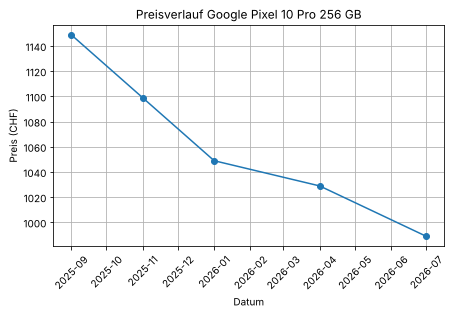

,datum,preis_raw,preis_chf
0,2025-09-01,CHF 1'149.–,1149
1,2025-11-01,CHF 1'099.–,1099
2,2026-01-01,CHF 1'049.–,1049
3,2026-04-01,CHF 1'029.–,1029
4,2026-07-01,CHF 989.–,989


In [8]:
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# Locate the table «Preisverlauf» (first table on the page)
table = soup.find_all('table')[0]

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame and remove the header row (no <td> cells)
df_C3 = pd.DataFrame(rows, columns=['datum', 'preis_raw']).dropna().reset_index(drop=True)

# Convert date and price
df_C3['datum'] = pd.to_datetime(df_C3['datum'], format='%d.%m.%Y')
df_C3['preis_chf'] = [int(''.join(re.findall(r"\d+", i))) for i in df_C3['preis_raw']]
print(df_C3.dtypes, '\n')

# Percentage change from the first to the last entry
change = (df_C3['preis_chf'].iloc[-1] - df_C3['preis_chf'].iloc[0]) / df_C3['preis_chf'].iloc[0] * 100
print('Preisänderung (%):', round(change, 1), '\n')

# Line chart of the price history
plt.figure(figsize=(7, 4))
plt.plot(df_C3['datum'], df_C3['preis_chf'], marker='o')
plt.title('Preisverlauf Google Pixel 10 Pro 256 GB', fontsize=12)
plt.xlabel('Datum')
plt.ylabel('Preis (CHF)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

df_C3

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 23–25 (Date Formatting: datetime in a data frame); Folien Woche 5, S. 28 (Line chart); AP02 C1 (Tabelle aus der Detailseite, `dropna()`).*

---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [9]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.18.44-fc-v310
Datetime: 2026-11-07 10:43:22
Python Version: 3.13.18
IP Address: 127.0.0.1
-----------------------------------
